In [1]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
from utils.cleaning import *
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, recall_score, auc, precision_score, roc_curve, average_precision_score, precision_recall_curve, confusion_matrix
from common.helper import load_data_and_scale_pos_weight
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
_, X_test, _, y_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True)

In [3]:
final_model = XGBClassifier()
final_model.load_model('../model/prauc_model2.ubj')

In [4]:
y1_pred = final_model.predict(X_test)
y1_pred_proba = final_model.predict_proba(X_test)
acc1 = accuracy_score(y_test, y1_pred)
conf1 = confusion_matrix(y_test, y1_pred)
precis1 = precision_score(y_test, y1_pred)
rec1 = recall_score(y_test, y1_pred)
f11 = f1_score(y_test, y1_pred)
fpr1, tpr1, thresholds_roc1 = roc_curve(y_test, y1_pred_proba[:, 1])
roc_auc1 = auc(fpr1, tpr1)

prec1, recall1, th1 = precision_recall_curve(y_test, y1_pred_proba[:, 1])
prauc1 = auc(recall1, prec1)

In [5]:
metrics_df = pd.DataFrame(
    data={
        "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUROC", "PR-AUC"],
        "Score": [acc1, precis1, rec1, f11, roc_auc1, prauc1]
    },
    index=[0, 1, 2, 3, 4, 5],
)
metrics_df

,Metric,Score
0,Accuracy,0.720425
1,Precision,0.307707
2,Recall,0.757729
3,F1-score,0.437677
4,AUROC,0.810670
5,PR-AUC,0.426928


In [6]:
y_test_classes = y_test.value_counts()
neg = y_test_classes[0]
pos = y_test_classes[1]
baseline_prauc = pos / (pos + neg)
print(f"pos={pos}, neg={neg}, baseline_prauc={baseline_prauc}")

pos=49874, neg=297464, baseline_prauc=0.1435892416032798


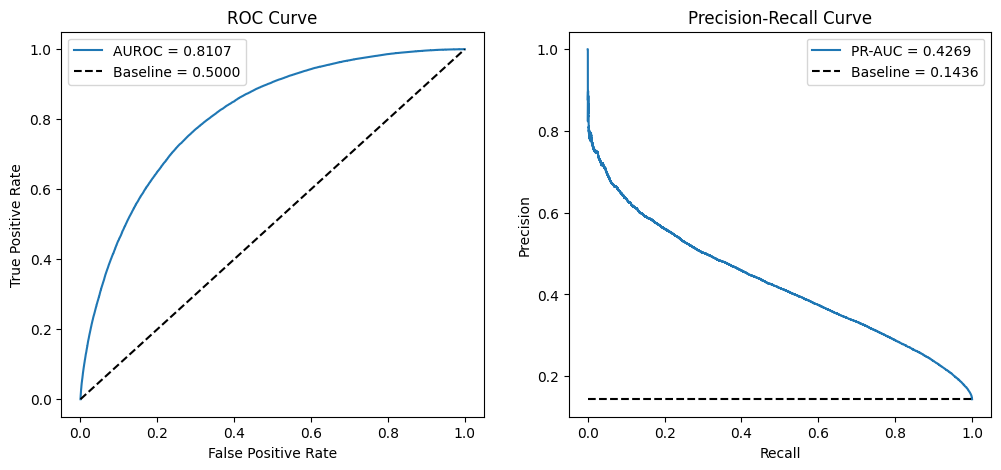

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(fpr1, tpr1, label=f'AUROC = {roc_auc1:.4f}')
ax[0].plot([0, 1], [0, 1], 'k--', label='Baseline = 0.5000') # Random baseline
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC Curve')
ax[0].legend()

ax[1].plot(recall1, prec1, label=f'PR-AUC = {prauc1:.4f}')
ax[1].plot([0, 1], [baseline_prauc, baseline_prauc], 'k--', label=f'Baseline = {baseline_prauc:.4f}') # Random baseline
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()

plt.show()

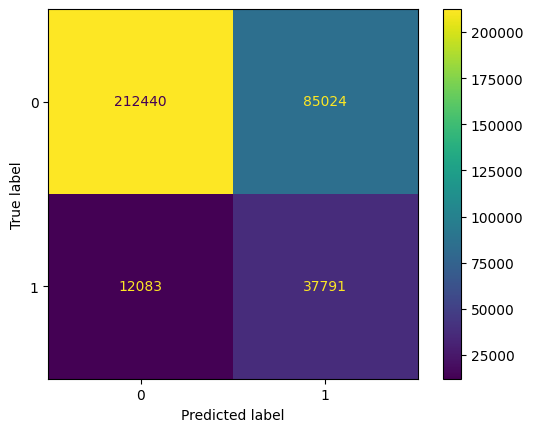

In [8]:
disp = ConfusionMatrixDisplay(conf1, display_labels=final_model.classes_)
disp.plot()